# Soft vs. Hard Constraints for a 1D Heat Equation

**Research question:** Does hard-enforcing the initial/boundary conditions improve PINN accuracy relative to the standard soft-penalty approach?

**Benchmark** (manufactured source; **not** a direct reproduction of Bowman et al.'s experimental data):

$$u_t-0.1u_{xx}=Q(x,t),\quad (x,t)\in[0,1]^2.$$

$$u^*(x,t)=e^{-t}\sin(\pi x)+0.2t\sin(3\pi x).$$

$$u(x,0)=\sin(\pi x),\qquad u(0,t)=u(1,t)=0.$$

**Soft model:** $u_\theta=N_\theta(x,t)$ and minimize $L_{PDE}+10L_{IC}+10L_{BC}$.

**Hard model:** $u_\theta=\sin(\pi x)+t\,x(1-x)N_\theta(x,t)$ and minimize $L_{PDE}$. This hard-enforces **IC/BC only**, not the PDE itself.

Both use the same 2–64–64–64–1 Tanh MLP, Adam ($10^{-3}$), **2,000 epochs**, the **same initial MLP weights**, and the **same interior PDE collocation batches at every epoch**. Evaluation is on a separate 101×101 test grid and 2,048 unseen PDE points. The reference field is not used as interior supervised training labels.

**Runs on CPU; no Matplotlib required.** Execute **Kernel → Restart & Run All** to reproduce the results. Outputs, CSV histories, and trained models are saved under `results/`; public synthetic reference data are saved under `data/`.

Reference inspiration: Bowman et al. (2023), [*Physics-Informed Neural Networks for the Heat Equation with Source Term under Various Boundary Conditions*](https://doi.org/10.3390/a16090428).

## 1. Reproducible training configuration

In [1]:
"""Reproducible soft vs hard PINN experiment for a 1D manufactured heat equation.

Run: python pinn_heat.py
Dependencies: torch, numpy, pillow; no download or Matplotlib required.
This is a methodological extension of the PINN approach, NOT a reproduction
of Bowman et al.'s proprietary heat-transfer data or numerical results.
"""
# %% 1. Imports and configuration
import csv
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import torch
from torch import nn
from PIL import Image, ImageDraw, ImageFont

SEED = 42
SOURCE_SEED = 314159           # same interior collocation samples for both models
EXTRA_SEED = 271828            # independent IC / BC samples for soft PINN
ALPHA = 0.1
EPOCHS = 2000
N_F, N_IC, N_BC = 256, 128, 128
LR = 1.0e-3
LAMBDA_IC = LAMBDA_BC = 10.0
GRID_SIZE = 101
DEVICE = torch.device("cpu")   # fixed for a comparable, reproducible local run
RESULTS = Path(__file__).resolve().parent / "results" if "__file__" in globals() else Path("results")
RESULTS.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
print(f"Device={DEVICE}, epochs={EPOCHS}, N_F={N_F}, seed={SEED}")



Device=cpu, epochs=2000, N_F=256, seed=42


## 2. Verify the heat equation and manufactured source

In [2]:
# %% 2. Benchmark equation and checks
# PDE: u_t - alpha*u_xx = Q(x,t) for (x,t) in [0,1]^2.
# u*(x,t) = exp(-t) sin(pi*x) + 0.2*t*sin(3*pi*x)
# u(x,0) = sin(pi*x), u(0,t) = u(1,t) = 0.
# Analytical u* is ONLY used for Q(x,t) manufacture, verification, evaluation.

def initial_u(x):
    return torch.sin(math.pi * x)


def exact_u(x, t):
    return torch.exp(-t) * torch.sin(math.pi * x) + 0.2 * t * torch.sin(3 * math.pi * x)


def heat_source(x, t):
    return ((ALPHA * math.pi ** 2 - 1) * torch.exp(-t) * torch.sin(math.pi * x)
            + 0.2 * (1 + 9 * ALPHA * math.pi ** 2 * t) * torch.sin(3 * math.pi * x))


xcheck = torch.rand((80, 2), requires_grad=True)
ucheck = exact_u(xcheck[:, :1], xcheck[:, 1:])
dcheck = torch.autograd.grad(ucheck, xcheck, torch.ones_like(ucheck), create_graph=True)[0]
dxx = torch.autograd.grad(dcheck[:, :1], xcheck,
                          torch.ones_like(ucheck), create_graph=True)[0][:, :1]
manufactured_max_residual = (dcheck[:, 1:] - ALPHA * dxx - heat_source(xcheck[:, :1], xcheck[:, 1:])).abs().max().item()
assert manufactured_max_residual < 2e-5
print(f"Manufactured PDE max residual = {manufactured_max_residual:.3e}")
del xcheck, ucheck, dcheck, dxx



Manufactured PDE max residual = 3.576e-07


## 3. Network definitions and PINN losses

In [3]:
# %% 3. Matched MLPs and losses
class HeatMLP(nn.Module):
    def __init__(self, width=64, depth=3):
        super().__init__()
        layers = [nn.Linear(2, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.Tanh()]
        layers += [nn.Linear(width, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, xt):
        return self.net(xt)


class HeatPINN(nn.Module):
    def __init__(self, mode):
        super().__init__()
        assert mode in {"soft", "hard"}
        self.mode = mode
        self.core = HeatMLP()

    def forward(self, xt):
        raw = self.core(xt)
        if self.mode == "soft":
            return raw
        x, t = xt[:, :1], xt[:, 1:]
        # Hard IC/BC: u(x,0) = sin(pi*x), u(0,t) = u(1,t) = 0
        # PDE is STILL enforced softly through the residual loss.
        return initial_u(x) + t * x * (1 - x) * raw


def pde_residual(model, x, t):
    xt = torch.cat([x, t], dim=1).detach().requires_grad_(True)
    u = model(xt)
    du = torch.autograd.grad(u, xt, torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(du[:, :1], xt,
                               torch.ones_like(u), create_graph=True)[0][:, :1]
    return du[:, 1:] - ALPHA * u_xx - heat_source(xt[:, :1], xt[:, 1:])


def sample_soft_constraint_loss(model, gen):
    x_ic = torch.rand(N_IC, 1, generator=gen)
    t_bc = torch.rand(N_BC, 1, generator=gen)
    ic = (model(torch.cat([x_ic, torch.zeros_like(x_ic)], 1)) - initial_u(x_ic)).square().mean()
    left = model(torch.cat([torch.zeros_like(t_bc), t_bc], 1))
    right = model(torch.cat([torch.ones_like(t_bc), t_bc], 1))
    bc = 0.5 * (left.square().mean() + right.square().mean())
    return ic, bc



## 4. Train matched Soft and Hard models

In [4]:
# %% 4. Train both with identical initialization / collocation samples

def train_one(mode):
    # Reset initialization and use a dedicated RNG for PDE point samples.
    # This guarantees same raw MLP initialization and same x_f,t_f batches.
    torch.manual_seed(SEED)
    model = HeatPINN(mode).to(DEVICE)
    interior_rng = torch.Generator(device="cpu").manual_seed(SOURCE_SEED)
    extra_rng = torch.Generator(device="cpu").manual_seed(EXTRA_SEED)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = []
    start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        x_f = torch.rand(N_F, 1, generator=interior_rng, device=DEVICE)
        t_f = torch.rand(N_F, 1, generator=interior_rng, device=DEVICE)
        optimizer.zero_grad(set_to_none=True)
        physics = pde_residual(model, x_f, t_f).square().mean()
        if mode == "soft":
            ic, bc = sample_soft_constraint_loss(model, extra_rng)
            loss = physics + LAMBDA_IC * ic + LAMBDA_BC * bc
        else:
            loss = physics
            # The hard IC/BC loss is structurally zero; this is NOT numerical penalty training.
            ic = physics.detach().new_zeros(())
            bc = physics.detach().new_zeros(())
        loss.backward()
        optimizer.step()
        row = dict(epoch=epoch, total=float(loss.detach()), physics=float(physics.detach()),
                   ic=float(ic.detach()), bc=float(bc.detach()))
        history.append(row)
        if epoch == 1 or epoch % 400 == 0 or epoch == EPOCHS:
            print(f"{mode:>4} | {epoch:>4}/{EPOCHS} | total={row['total']:.3e} "
                  f"PDE={row['physics']:.3e} IC={row['ic']:.3e} BC={row['bc']:.3e}")
    elapsed = time.perf_counter() - start
    with (RESULTS / f"{mode}_history.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["epoch", "total", "physics", "ic", "bc"])
        writer.writeheader()
        writer.writerows(history)
    torch.save(model.state_dict(), RESULTS / f"{mode}_model.pt")
    return model, history, elapsed


models, histories, elapsed_times = {}, {}, {}
for mode in ("soft", "hard"):
    models[mode], histories[mode], elapsed_times[mode] = train_one(mode)



soft |    1/2000 | total=9.478e+00 PDE=7.727e-01 IC=8.228e-01 BC=4.770e-02


soft |  400/2000 | total=1.299e-01 PDE=1.131e-01 IC=9.099e-04 BC=7.721e-04


soft |  800/2000 | total=9.891e-03 PDE=8.180e-03 IC=6.523e-05 BC=1.058e-04


soft | 1200/2000 | total=4.313e-03 PDE=3.717e-03 IC=1.596e-05 BC=4.365e-05


soft | 1600/2000 | total=3.257e-03 PDE=2.773e-03 IC=2.226e-05 BC=2.607e-05


soft | 2000/2000 | total=3.291e-03 PDE=1.819e-03 IC=8.801e-05 BC=5.922e-05
hard |    1/2000 | total=1.243e+00 PDE=1.243e+00 IC=0.000e+00 BC=0.000e+00


hard |  400/2000 | total=2.073e-03 PDE=2.073e-03 IC=0.000e+00 BC=0.000e+00


hard |  800/2000 | total=6.763e-04 PDE=6.763e-04 IC=0.000e+00 BC=0.000e+00


hard | 1200/2000 | total=1.296e-04 PDE=1.296e-04 IC=0.000e+00 BC=0.000e+00


hard | 1600/2000 | total=8.096e-05 PDE=8.096e-05 IC=0.000e+00 BC=0.000e+00


hard | 2000/2000 | total=9.676e-05 PDE=9.676e-05 IC=0.000e+00 BC=0.000e+00


## 5. Evaluate on the same unseen test points

In [5]:
# %% 5. Evaluation: same exact solution, dense grid, unseen PDE points

def evaluate_one(mode, model, seconds):
    grid = torch.linspace(0, 1, GRID_SIZE)
    xx, tt = torch.meshgrid(grid, grid, indexing="ij")
    xt = torch.stack([xx.reshape(-1), tt.reshape(-1)], dim=1)
    model.eval()
    with torch.no_grad():
        pred = model(xt).reshape(GRID_SIZE, GRID_SIZE)
        exact = exact_u(xx, tt)
        rel_l2 = ((pred - exact).norm() / exact.norm()).item()
        ic_rmse = ((pred[:, 0] - exact[:, 0]).square().mean().sqrt()).item()
        bc_rmse = (0.5 * (pred[0, :].square().mean() + pred[-1, :].square().mean())).sqrt().item()
    # Held-out interior PDE samples; no training labels are used.
    gen = torch.Generator(device="cpu").manual_seed(123456)
    xf = torch.rand(2048, 1, generator=gen)
    tf = torch.rand(2048, 1, generator=gen)
    residual_rmse = (pde_residual(model, xf, tf).detach().square().mean().sqrt()).item()
    info = dict(mode=mode, benchmark="manufactured_1d_heat", seed=SEED, epochs=EPOCHS,
                model="2-64-64-64-1, Tanh", alpha=ALPHA, n_f_per_epoch=N_F,
                n_ic=N_IC if mode == "soft" else 0, n_bc=N_BC if mode == "soft" else 0,
                optimizer="Adam", learning_rate=LR,
                lambda_ic=LAMBDA_IC if mode == "soft" else 0,
                lambda_bc=LAMBDA_BC if mode == "soft" else 0,
                training_seconds=seconds, relative_l2=rel_l2, ic_rmse=ic_rmse,
                bc_rmse=bc_rmse, pde_rmse_heldout=residual_rmse,
                device=str(DEVICE), grid_size=GRID_SIZE)
    (RESULTS / f"{mode}_metrics.json").write_text(json.dumps(info, indent=2), encoding="utf-8")
    return info, pred.detach().cpu().numpy(), exact.detach().cpu().numpy()


metrics, preds = {}, {}
for mode in ("soft", "hard"):
    metrics[mode], preds[mode], truth_np = evaluate_one(mode, models[mode], elapsed_times[mode])
print("\nHEAD-TO-HEAD METRICS (same initialization, PDE samples, architecture, steps)")
for mode in ("soft", "hard"):
    m = metrics[mode]
    print(f"{mode:>4}: relL2={100*m['relative_l2']:.4f}%, IC={m['ic_rmse']:.3e}, "
          f"BC={m['bc_rmse']:.3e}, PDE={m['pde_rmse_heldout']:.3e}, "
          f"seconds={m['training_seconds']:.1f}")
(RESULTS / "comparison_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")




HEAD-TO-HEAD METRICS (same initialization, PDE samples, architecture, steps)
soft: relL2=2.4099%, IC=8.663e-03, BC=9.099e-03, PDE=4.212e-02, seconds=10.6
hard: relL2=0.0885%, IC=0.000e+00, BC=6.182e-08, PDE=7.585e-03, seconds=9.9


1120

## 6. Generate figures and public benchmark data

In [6]:
# %% 6. Pillow visualizations: avoid Matplotlib crashes on Windows

def load_font(size, bold=False):
    options = (["DejaVuSans-Bold.ttf", "arialbd.ttf"] if bold else
               ["DejaVuSans.ttf", "arial.ttf"])
    for font in options:
        try:
            return ImageFont.truetype(font, size)
        except OSError:
            continue
    return ImageFont.load_default()


def plot_pde_history():
    w, h = 1120, 625
    image = Image.new("RGB", (w, h), "white")
    d = ImageDraw.Draw(image)
    regular, titlefont = load_font(21), load_font(28, True)
    x0, x1, y0, y1 = 120, 1060, 100, 520
    arrays = [np.array([r["physics"] for r in histories[m]], dtype=float) for m in ("soft", "hard")]
    logs = [np.log10(np.maximum(a, 1e-15)) for a in arrays]
    lo = math.floor(min(float(v.min()) for v in logs))
    hi = math.ceil(max(float(v.max()) for v in logs))
    if lo == hi:
        hi += 1
    for p in range(lo, hi + 1):
        yp = int(y1 - (p - lo) / (hi - lo) * (y1 - y0))
        d.line((x0, yp, x1, yp), fill=(226, 232, 240))
        d.text((28, yp - 13), f"10^{p}", font=regular, fill=(64, 69, 79))
    for epoch in range(0, EPOCHS+1, 400):
        xp = int(x0 + epoch / EPOCHS * (x1 - x0))
        d.line((xp, y0, xp, y1), fill=(239, 242, 246))
        d.text((xp - 26, y1 + 12), str(epoch), font=regular, fill=(64, 69, 79))
    d.rectangle((x0, y0, x1, y1), outline=(83, 89, 101), width=2)
    colors = {"soft": (44, 111, 186), "hard": (218, 95, 55)}
    for mode, log in zip(("soft", "hard"), logs):
        points = [(int(x0 + i/(EPOCHS-1)*(x1-x0)),
                   int(y1-(float(y)-lo)/(hi-lo)*(y1-y0))) for i, y in enumerate(log)]
        d.line(points, fill=colors[mode], width=3, joint="curve")
    d.text((260, 30), "Training PDE residual MSE", fill=(30, 40, 55), font=titlefont)
    d.line((770, 78, 810, 78), fill=colors["soft"], width=5)
    d.text((817, 65), "Soft PINN", font=regular, fill=(40, 50, 60))
    d.line((925, 78, 965, 78), fill=colors["hard"], width=5)
    d.text((974, 65), "Hard PINN", font=regular, fill=(40, 50, 60))
    d.text((515, 574), "Epoch", font=regular, fill=(45, 55, 65))
    path = RESULTS / "pde_loss_comparison.png"
    image.save(path)
    return path


def colormap(a, low, high):
    # Fixed blue-teal-yellow-red palette, numerical data -> RGB.
    stops = np.array([0.0, 0.25, 0.5, 0.75, 1.0])
    rgb = np.array([[30,42,106], [40,131,183], [116,199,164], [246,216,115], [204,64,61]])
    v = np.clip((a - low)/(high - low + 1e-14), 0, 1)
    return np.stack([np.interp(v, stops, rgb[:,c]) for c in range(3)], axis=-1).astype(np.uint8)


def plot_prediction_comparison():
    fields = [truth_np, preds["soft"], preds["hard"],
              np.abs(preds["soft"]-truth_np), np.abs(preds["hard"]-truth_np)]
    labels = ["Exact solution", "Soft prediction", "Hard prediction", "Soft absolute error", "Hard absolute error"]
    low = min(float(x.min()) for x in fields[:3])
    high = max(float(x.max()) for x in fields[:3])
    err_max = max(float(x.max()) for x in fields[3:])
    w, h, stride, size = 1780, 470, 350, 294
    canvas = Image.new("RGB", (w, h), "white")
    d = ImageDraw.Draw(canvas)
    small, medium = load_font(17), load_font(20, True)
    for j, (field, label) in enumerate(zip(fields, labels)):
        xleft = j * stride + 15
        vmin, vmax = (low, high) if j < 3 else (0, err_max)
        a = colormap(field.T[::-1, :], vmin, vmax)
        tile = Image.fromarray(a).resize((size, size), resample=Image.Resampling.BILINEAR)
        canvas.paste(tile, (xleft + 32, 78))
        d.rectangle((xleft+32, 78, xleft+32+size, 78+size), outline=(49, 59, 69), width=2)
        d.text((xleft + 32, 30), label, font=medium, fill=(33, 42, 56))
        d.text((xleft+174, 387), "x", font=small, fill=(65, 70, 80))
        d.text((xleft+10, 208), "t", font=small, fill=(65, 70, 80))
        d.text((xleft+32, 411), f"scale: [{vmin:.3g}, {vmax:.3g}]", font=small, fill=(75, 80, 88))
    out = RESULTS / "predictions_comparison.png"
    canvas.save(out)
    return out


loss_image = plot_pde_history()
pred_image = plot_prediction_comparison()
print(f"Saved images: {loss_image.name}, {pred_image.name}")

# Export a small public reference dataset. It is NEVER loaded during training.
DATA_DIR = RESULTS.parent / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
coords = np.linspace(0, 1, GRID_SIZE)
with (DATA_DIR / "reference_grid_101x101.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["x", "t", "u_exact", "source_q"])
    with torch.no_grad():
        for ix, x in enumerate(coords):
            xxrow = torch.full((GRID_SIZE, 1), float(x), dtype=torch.float32)
            trow = torch.tensor(coords, dtype=torch.float32).reshape(-1, 1)
            q = heat_source(xxrow, trow).numpy().reshape(-1)
            for it, t in enumerate(coords):
                writer.writerow([f"{x:.8f}", f"{t:.8f}",
                                 f"{float(truth_np[ix, it]):.10f}", f"{float(q[it]):.10f}"])
print(f"Saved test-only reference dataset: {DATA_DIR / 'reference_grid_101x101.csv'}")



Saved images: pde_loss_comparison.png, predictions_comparison.png


Saved test-only reference dataset: data/reference_grid_101x101.csv


## 7. Validate completion and report results

In [7]:
# %% 7. Assertions and summary
assert len(histories["soft"]) == EPOCHS and len(histories["hard"]) == EPOCHS
assert all(math.isfinite(m["relative_l2"]) for m in metrics.values())
assert metrics["hard"]["ic_rmse"] < 1e-6, "Hard IC not satisfied"
assert metrics["hard"]["bc_rmse"] < 1e-6, "Hard BC not satisfied"
print("All checks passed: matched 2,000-epoch runs, finite scores, hard constraints within float32 precision.")


All checks passed: matched 2,000-epoch runs, finite scores, hard constraints within float32 precision.


## Result figures (embedded from generated PNG files)

predictions_comparison.png


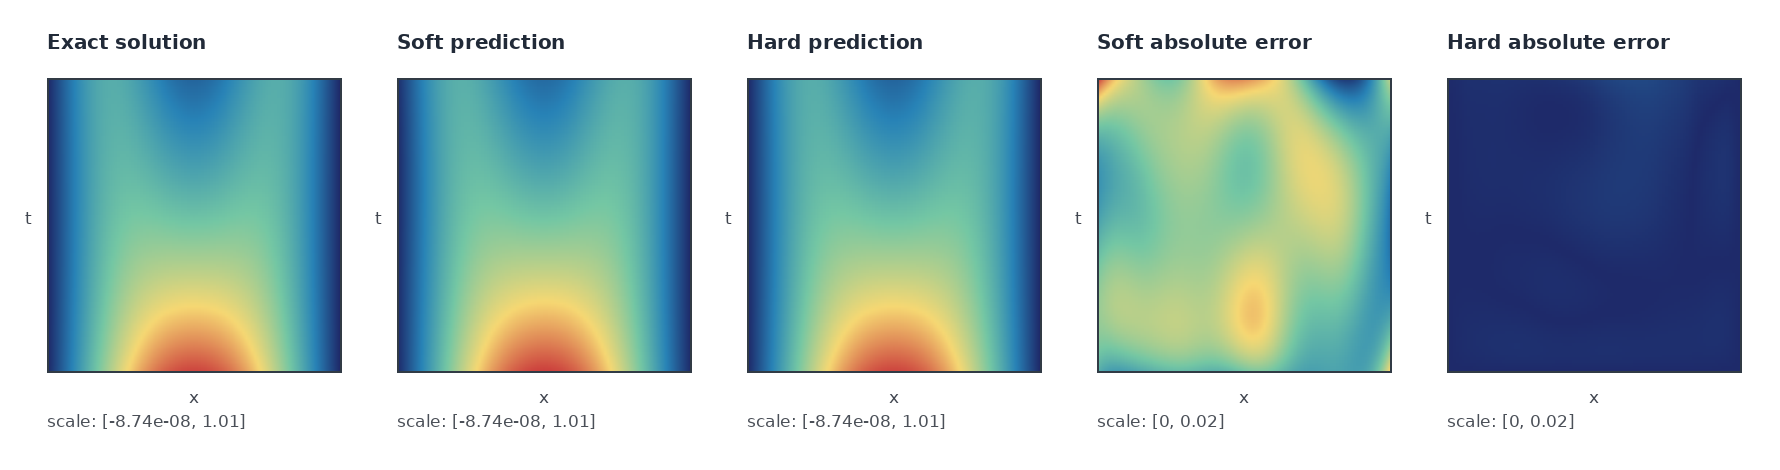

pde_loss_comparison.png


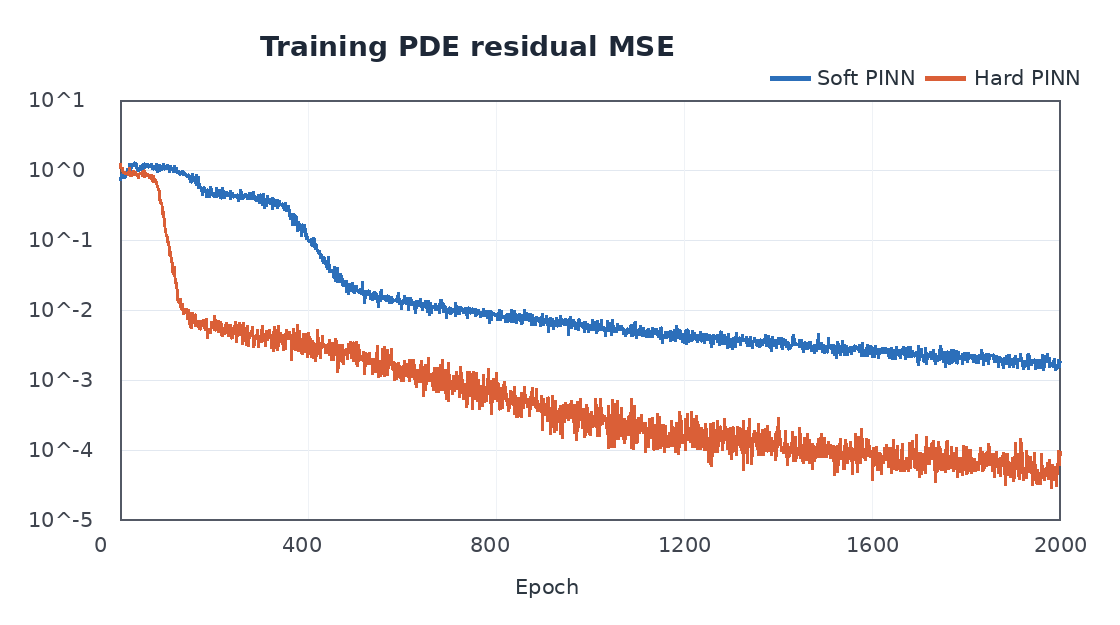

In [8]:
from IPython.display import display, Image as IPImage
for filename in ("predictions_comparison.png", "pde_loss_comparison.png"):
    print(filename)
    display(IPImage(filename=str(RESULTS / filename)))
